<a href="https://colab.research.google.com/github/durgajc/portfolio_durga/blob/ai-ml/Densitybasedclustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import libraries
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt


In [2]:
# Step 1: Load the dataset
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names


In [3]:
# Step 2: Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [4]:
# Step 3: Reduce features using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)


In [5]:
# Step 4: Apply DBSCAN clustering
dbscan = DBSCAN(eps=0.5, min_samples=5)
clusters = dbscan.fit_predict(X_pca)


In [6]:
# Step 5: Create a DataFrame for better visualization
df = pd.DataFrame(X_pca, columns=['PCA1', 'PCA2'])
df['Cluster'] = clusters


In [7]:
# Step 6: Display results
print("Cluster labels assigned by DBSCAN:")
print(np.unique(clusters))
print("\nNumber of clusters excluding noise:", len(set(clusters)) - (1 if -1 in clusters else 0))


Cluster labels assigned by DBSCAN:
[-1  0  1]

Number of clusters excluding noise: 2


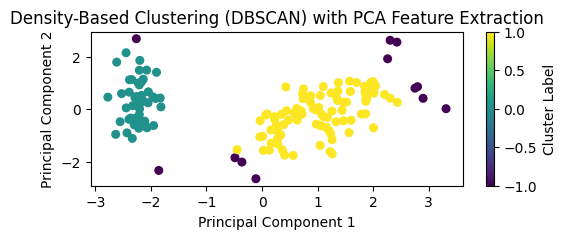

In [8]:
# Step 7: Visualize the clusters
plt.figure(figsize=(6,2))
plt.scatter(df['PCA1'], df['PCA2'], c=df['Cluster'], cmap='viridis', s=30)
plt.title('Density-Based Clustering (DBSCAN) with PCA Feature Extraction')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(label='Cluster Label')
plt.show()
